*Notebook 01 in `notebooks/arcs/`. Parameters (pre-registered): `analysis/arcs/config.yaml`; decisions and run notes: `analysis/arcs/LOG.md`. The static page `site/arcs/index.html` is built from the same saved outputs.*

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve().parents[1]   # notebooks/arcs -> repo root
sys.path.insert(0, str(REPO))

import warnings

import pandas as pd
import plotly.io as pio
from IPython.display import Markdown, display

from analysis.scripts_text.report import nb_md
from analysis.static_figures import use_static_figures

from analysis.arcs import s01_sample as step

use_static_figures()   # figures become static PNGs (they show on GitHub); interactive ones are on the static page
warnings.filterwarnings("ignore", category=RuntimeWarning)   # known 0/0 on very short arcs, handled downstream
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

## Step 1 · Sample and outcome

Which films do we study, and how is their box-office success spread out?

Before we measure anything, we rebuild the sample from the repo's own rules and check that it lands on the
feasibility numbers. Then we describe the outcome, log(gross / budget), in the primary sample.

### The sample, step by step
- Start from clean theatrical films with a US-dollar budget and gross and 100,000+ IMDb votes. We don't use
  the 10k tier, because its money fields aren't validated.
- Keep the films with a MovieSum screenplay that has scene and dialogue markup.
- Drop the 8 scripts whose dialogue markup failed.
- For the **primary sample**, also drop films that are likely part of a franchise (Wikidata says the film
  "follows" another one, or names its franchise). We made this choice after the earlier word-level analysis,
  where the signal vanished once franchise films were left out. We say that openly, and Steps 9 and 10 rerun
  everything with all scripts.

### Why a continuous outcome
The earlier branch compared the bottom and top quarters of films. That threw away the middle half of the data
and the ordering inside each quarter. A correlation on the continuous outcome uses every film, so it has more
power with the same number of films.

### What it measures
log(gross / budget). A value of 0 means the film grossed exactly its budget, 1 means about 2.7 times its
budget, and 2 about 7.4 times. Taking the log stops a few huge multiples from dominating.

### What it misses
Gross / budget is **not profit**:
- Marketing isn't in the budget.
- Cinemas keep a large share of the gross.
- Nothing is adjusted for inflation. The ratio still compares like with like, because budget and gross are in
  the same year's dollars.
- The ratio favours micro-budget films, horror especially. A cheap film can earn 50 times its budget, a
  blockbuster rarely more than 5.

> **Takeaway.** The rebuilt sample matches the feasibility numbers. The primary sample has 868 non-franchise films with a usable screenplay (before Step 2's arc-ready filter). Its median film grossed 3.45× its budget, against 3.41× for all clean films.

In [2]:
res = step.run()   # recomputes this step and saves its outputs

**Table.** How the sample is built, step by step, rebuilt from the raw data. The 'expected' column holds the feasibility numbers, and a mismatch would stop the analysis.

In [3]:
display(step.tables(res)["funnel"])

,stage,films,expected,note
0,"Clean theatrical USD films, 100k+ IMDb votes",2446,2446,scripts/imdb/coverage_clean_sample.sql
1,… with a usable MovieSum script (≥ 1 scene and ≥ 1 dialogue tag; longest of 12 duplicates),1095,1095,
2,… minus scripts whose dialogue markup failed (< 500 dialogue words),1087,1087,excluded: 8
3,"… not likely franchise (PRIMARY, before the arc-ready filter of Step 2)",868,868,"likely franchise: 219 (follows 146, named 133, both 60)"
4,Scripts with Tag Genome reviews (Step 11 frame),946,946,no film after 2017
5,… not likely franchise,759,759,


**Figure.** log(gross/budget) for all clean films (grey), the primary sample (blue, hatched) and the franchise films we set aside (orange, crossed). Bars show the share of each sample. If the primary sample were a narrow slice of hits, its blue bars would sit to the right of the grey ones and cover a narrower range. The table below gives the numbers.

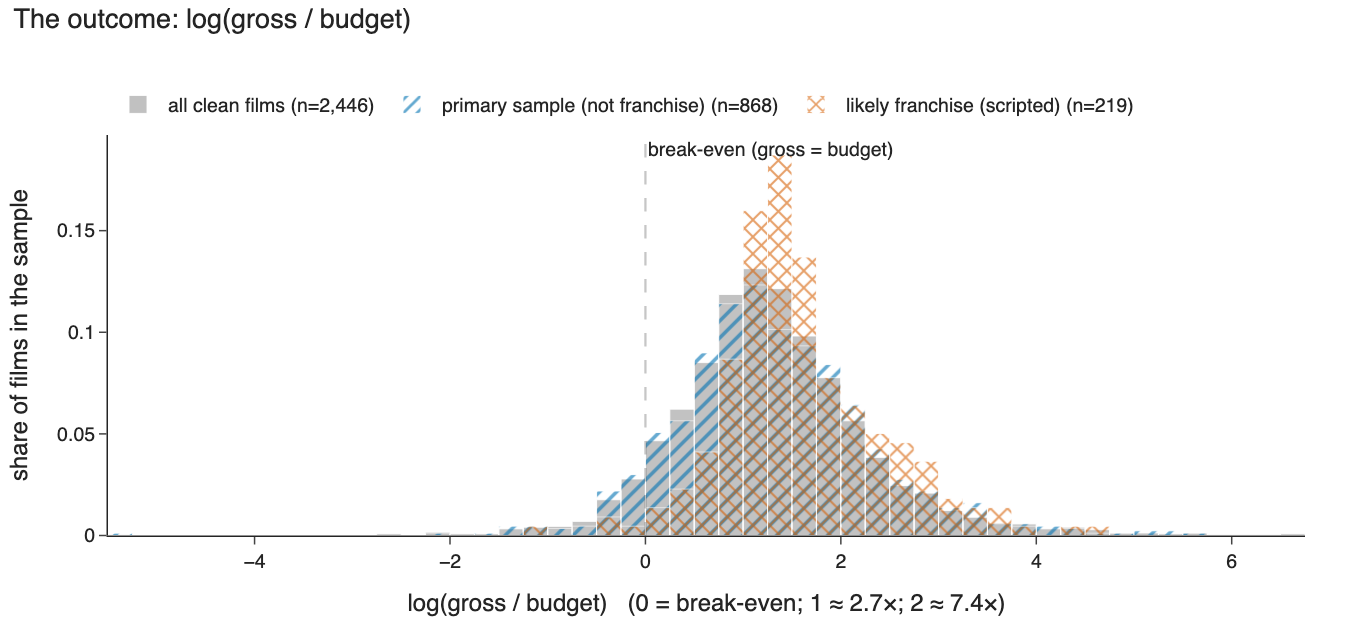

In [4]:
step.figures(res)["outcome"].show()

**Table.** The outcome in three samples: spread (SD), range, quartiles, and the share of films that grossed less than their budget.

In [5]:
display(step.tables(res)["outcome"])

,sample,films,mean,SD,min,Q1,Q3,max,share gross < budget,median multiple (×)
0,all clean films,2446,1.294,1.026,-6.06,0.71,1.79,6.73,0.069,3.41
1,"scripted (1,087)",1087,1.379,1.006,-5.28,0.79,1.90,5.53,0.062,3.69
2,primary: not franchise,868,1.323,1.040,-5.28,0.70,1.86,5.53,0.073,3.45


**Table.** Does the script sample lean towards hits? We count films in the bottom and top quarters the earlier branch used (cut-offs from all 2,446 clean films), for all scripted films and for the primary sample. With no lean the two counts would be about equal (top / bottom ≈ 1).

In [6]:
display(step.tables(res)["skew"])

,sample,earlier definition,bottom quarter (scripts),top quarter (scripts),top / bottom
0,"scripted (1,087)",B: quarters of all clean films,242,304,1.26
1,"scripted (1,087)",C: quarters within genre × decade cells,236,290,1.23
2,primary: not franchise,B: quarters of all clean films,223,235,1.05
3,primary: not franchise,C: quarters within genre × decade cells,220,213,0.97


**Figure.** Budgets of the primary films, on a log scale. They run from under a million to hundreds of millions of dollars, which is why we control for log budget.

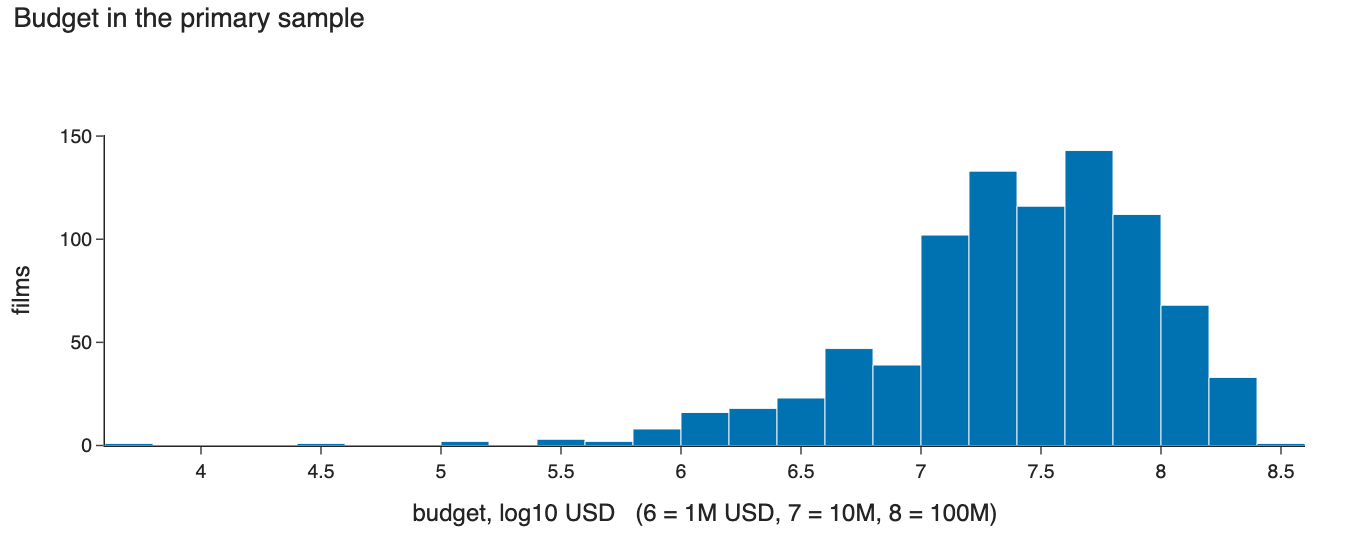

In [7]:
step.figures(res)["budget"].show()

**Figure.** Each dot is a primary film: budget (x) against log(gross/budget) (y). Cheap films spread much more widely in y, so we have to control for budget before relating anything else to the outcome.

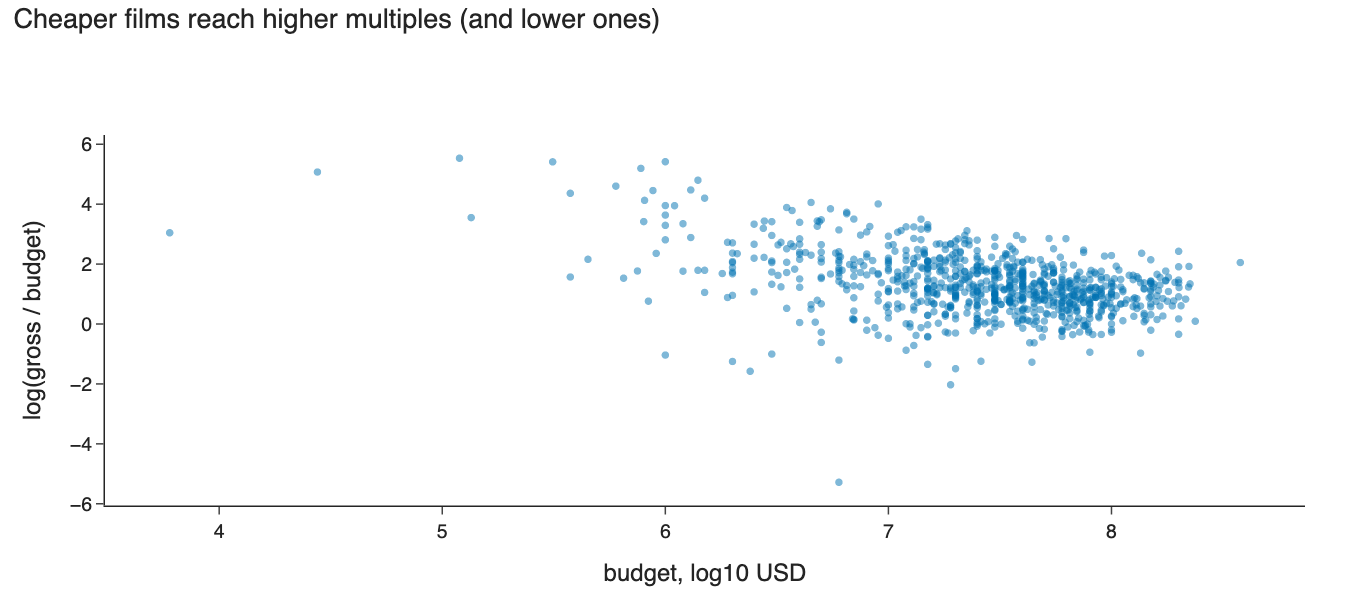

In [8]:
step.figures(res)["budget_vs_outcome"].show()

**Table.** Budget percentiles for the scripted films, the primary sample and the franchise films. Franchise films cost much more, which is one reason to treat them separately.

In [9]:
display(step.tables(res)["budget"])

,sample,films,P10 ($M),P25 ($M),P50 ($M),P75 ($M),P90 ($M),median log(gross/budget)
0,"scripted (1,087)",1087,5.0,15.0,35.0,75.0,140.0,1.305
1,primary: not franchise,868,4.5,13.2,30.0,62.1,102.0,1.238
2,likely franchise,219,12.8,29.0,69.0,141.2,200.0,1.455


**Figure.** How many primary films fall in each primary-genre × decade cell. These cells are the fixed effects of the analysis, so a film is compared with others from the same genre and decade. Genre follows the frozen priority rule (Horror, Sci-Fi, Thriller, Adventure, Action, Comedy, Drama). Cells with fewer than 5 films are pooled, so no film is compared only with itself.

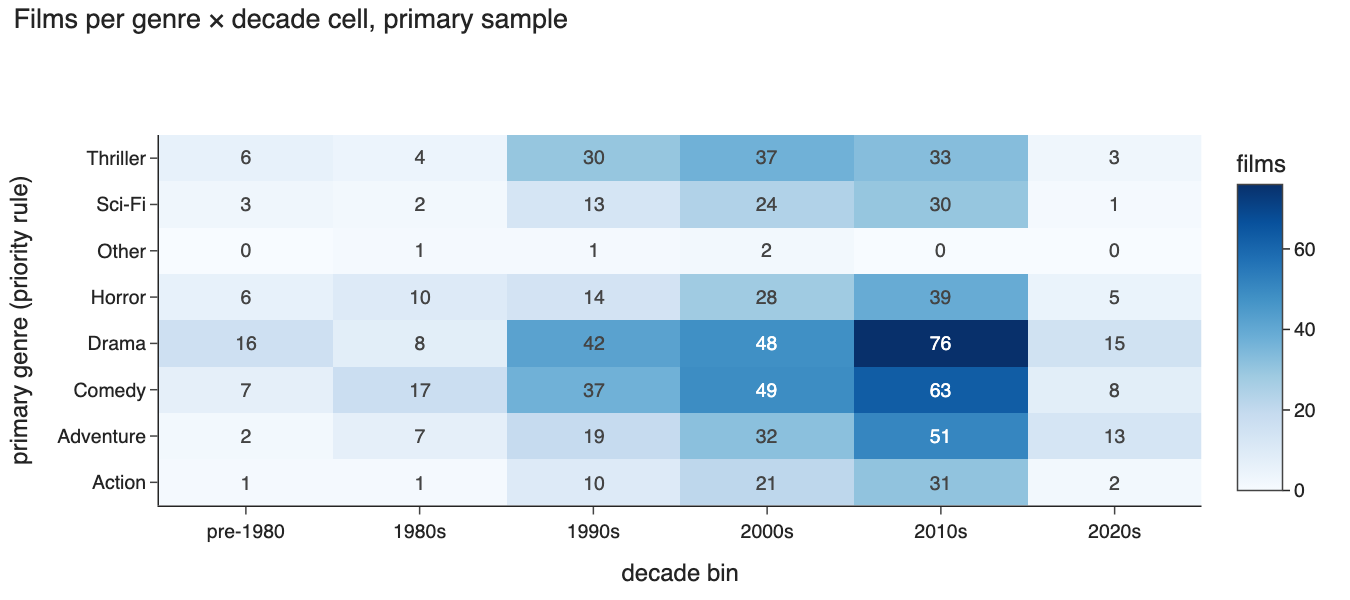

In [10]:
step.figures(res)["cells"].show()

**Table.** The same counts as a table.

In [11]:
display(step.tables(res)["composition"])

decade_bin,primary genre,pre-1980,1980s,1990s,2000s,2010s,2020s,all
0,Action,1,1,10,21,31,2,66
1,Adventure,2,7,19,32,51,13,124
2,Comedy,7,17,37,49,63,8,181
3,Drama,16,8,42,48,76,15,205
4,Horror,6,10,14,28,39,5,102
5,Other,0,1,1,2,0,0,4
6,Sci-Fi,3,2,13,24,30,1,73
7,Thriller,6,4,30,37,33,3,113
8,all,41,50,166,241,323,47,868


**Plain-language reading** (generated from the saved numbers):

In [12]:
display(Markdown(nb_md(step.reading(res))))

All six funnel numbers match the feasibility note (2,446, 1,095, 1,087, 868, 946, 759). The scripted films lean towards hits. Their median film grossed 3.69× its budget, against 3.41× for all clean films, and 304 scripts fall in the top quarter against 242 in the bottom (290 vs 236 when the quarters are cut within genre × decade cells). Most of that lean comes from franchise films. In the primary sample the counts are 235 vs 223 (213 vs 220 within cells), the median multiple is 3.45×, 7.3% grossed less than their budget (all clean films: 6.9%), and the SD of log(gross/budget) is 1.04 (all clean films: 1.03). So the restricted range the project brief expects is small in the primary sample. It's mainly a property of the scripted sample as a whole. The selection still isn't random, though: these are films popular enough to get 100,000+ IMDb votes and to have a public screenplay. Once genre × decade cells and log budget are taken out, the SD left to explain is 0.91. 23 primary films sit in cells with fewer than 5 films, so they're pooled (36 cells in all). Tag Genome reviews stop at 2017.